# Normalization

Normalization is a technique often used as part of data preparation for machine learning. The goal is to change the values of numerical columns in a dataset so they use a common scale while preserving the relative differences between values within each column.

## 1. Min-Max Normalization

Min-max normalization maps the smallest training value to `0` and the largest to `1`. It preserves the order and relative spacing of values.

$$
x_{\text{scaled}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$$

**Example:** `[10, 20, 30]` becomes `[0, 0.5, 1]`.

**In practice:** Calculate the minimum and maximum from the training data and reuse them for validation and test data. New values outside the training range can scale below `0` or above `1`.

In [45]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
np.random.seed(42)
weight = np.random.randint(40, 80, 10)
weight

array([78, 68, 54, 47, 60, 78, 58, 62, 50, 50])

In [19]:
weight_min_max_scaled = (weight - weight.min() ) / (weight.max() - weight.min()) 
weight_min_max_scaled

array([1.        , 0.67741935, 0.22580645, 0.        , 0.41935484,
       1.        , 0.35483871, 0.48387097, 0.09677419, 0.09677419])

In [23]:
url = "https://raw.githubusercontent.com/campusx-official/100-days-of-machine-learning/main/day25-normalization/wine_data.csv"
df = pd.read_csv(url, header=None, usecols=[0,1,2])
df.columns = ["class label", "alcohol", "malic acid"]
df.head()

,class label,alcohol,malic acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59


<Axes: xlabel='malic acid', ylabel='Density'>

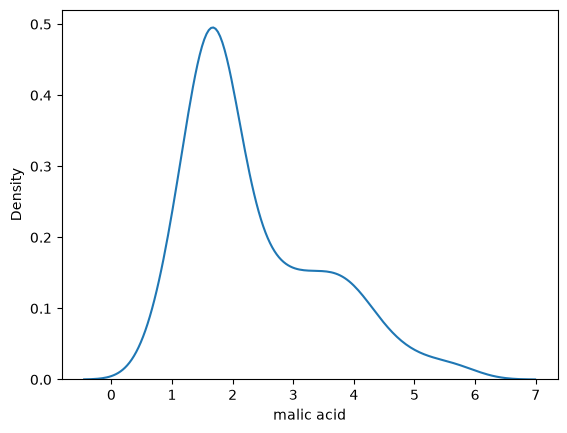

In [29]:
sns.kdeplot(df["malic acid"])

<Axes: xlabel='alcohol', ylabel='Density'>

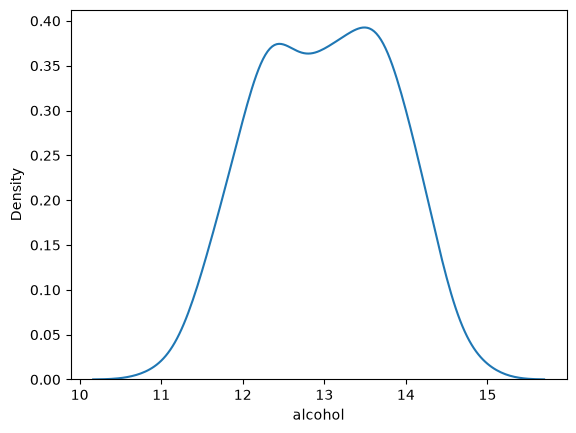

In [30]:
sns.kdeplot(df["alcohol"])

<Axes: xlabel='alcohol', ylabel='malic acid'>

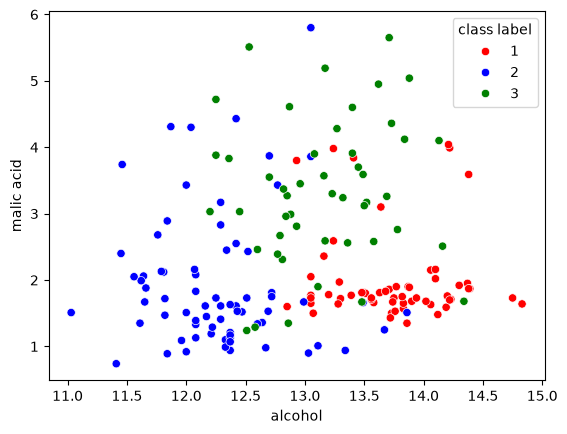

In [34]:
color_dict = {1: "red", 2: "blue", 3: "green"}
sns.scatterplot( data=df, x="alcohol", y="malic acid", hue="class label", palette=color_dict)

In [36]:
X = df[["alcohol", "malic acid"]]
y = df["class label"]

In [39]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,
                                                   test_size=0.2,
                                                   random_state=2)

In [40]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

scaler.fit(X_train, y_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [41]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [42]:
X_train.describe()

,alcohol,malic acid
count,142.000000,142.000000
mean,12.952958,2.356620
std,0.794066,1.164352
min,11.030000,0.890000
25%,12.332500,1.530000
50%,13.010000,1.820000
75%,13.610000,3.157500
max,14.830000,5.800000


In [43]:
X_train_scaled.describe()

,alcohol,malic acid
count,142.000000,142.000000
mean,0.506042,0.298701
std,0.208965,0.237139
min,0.000000,0.000000
25%,0.342763,0.130346
50%,0.521053,0.189409
75%,0.678947,0.461813
max,1.000000,1.000000


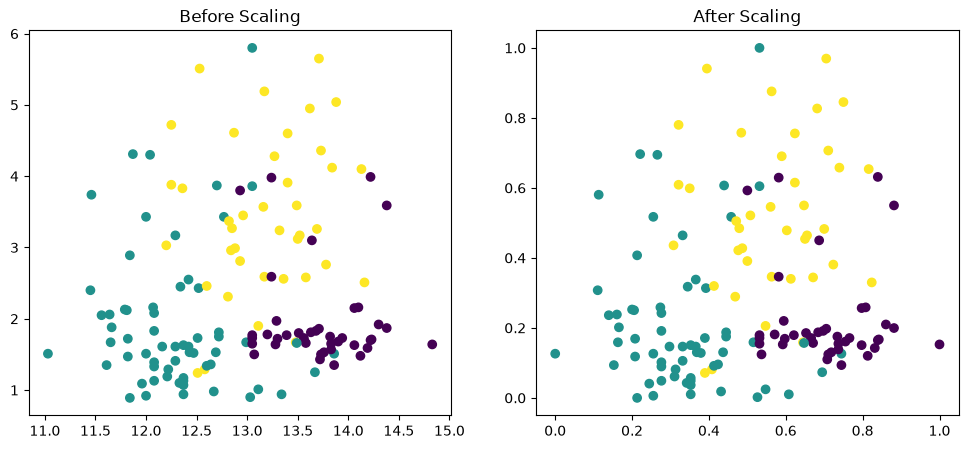

In [46]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['alcohol'], X_train['malic acid'],c=y_train)
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['alcohol'], X_train_scaled['malic acid'],c=y_train)
ax2.set_title("After Scaling")
plt.show()

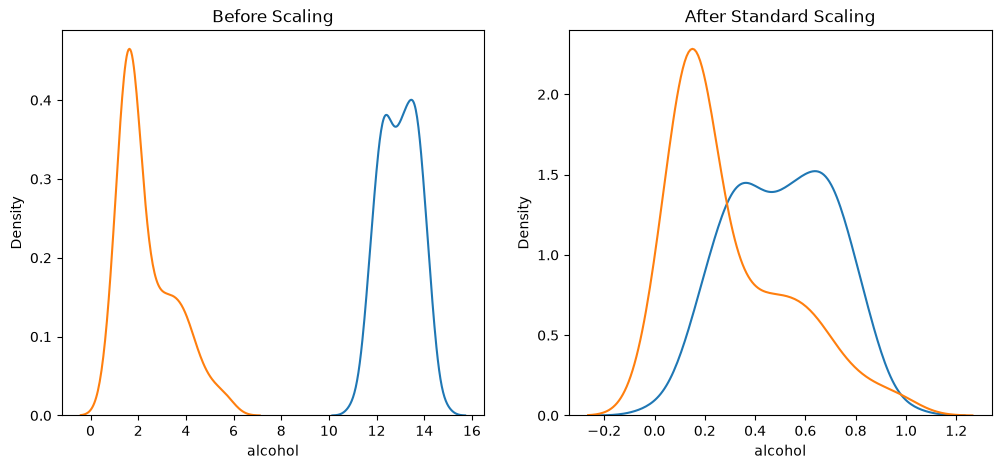

In [47]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['alcohol'], ax=ax1)
sns.kdeplot(X_train['malic acid'], ax=ax1)

# after scaling
ax2.set_title('After Standard Scaling')
sns.kdeplot(X_train_scaled['alcohol'], ax=ax2)
sns.kdeplot(X_train_scaled['malic acid'], ax=ax2)
plt.show()

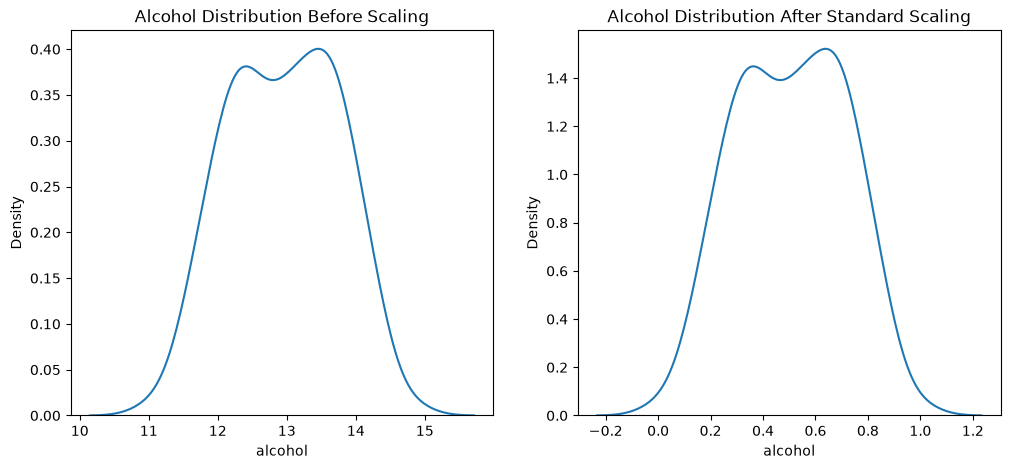

In [48]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Alcohol Distribution Before Scaling')
sns.kdeplot(X_train['alcohol'], ax=ax1)

# after scaling
ax2.set_title('Alcohol Distribution After Standard Scaling')
sns.kdeplot(X_train_scaled['alcohol'], ax=ax2)
plt.show()

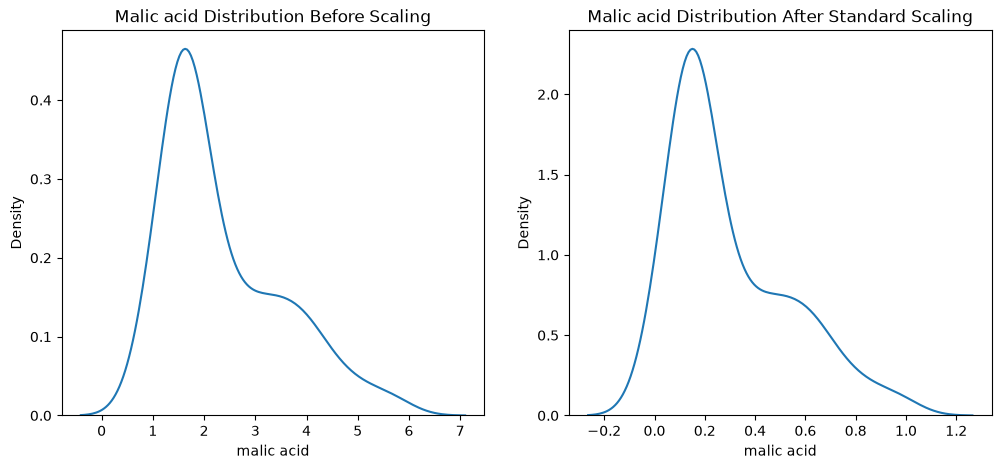

In [49]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('Malic acid Distribution Before Scaling')
sns.kdeplot(X_train['malic acid'], ax=ax1)

# after scaling
ax2.set_title('Malic acid Distribution After Standard Scaling')
sns.kdeplot(X_train_scaled['malic acid'], ax=ax2)
plt.show()

## 2. Mean normalization
- Mean centring

In [50]:
weight

array([78, 68, 54, 47, 60, 78, 58, 62, 50, 50])

In [52]:
weight_scaled = (weight - weight.mean()) / (weight.max() - weight.min())
weight_scaled

array([ 0.56451613,  0.24193548, -0.20967742, -0.43548387, -0.01612903,
        0.56451613, -0.08064516,  0.0483871 , -0.33870968, -0.33870968])

## 3. MaxAbsScaling

In [60]:
weight_scaled = weight / weight.max()
weight_scaled

array([1.        , 0.87179487, 0.69230769, 0.6025641 , 0.76923077,
       1.        , 0.74358974, 0.79487179, 0.64102564, 0.64102564])

In [61]:
from sklearn.preprocessing import MaxAbsScaler   # useful for sparse data

## Robust Scaling
- Robust to outliers

In [62]:
from sklearn.preprocessing import RobustScaler

- first ask is feature scaling required ?
- MinMax - when we already know min max values (image)
- sparse matrix  - MaxAbsScaling
- outliers - Robustscaler